In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs

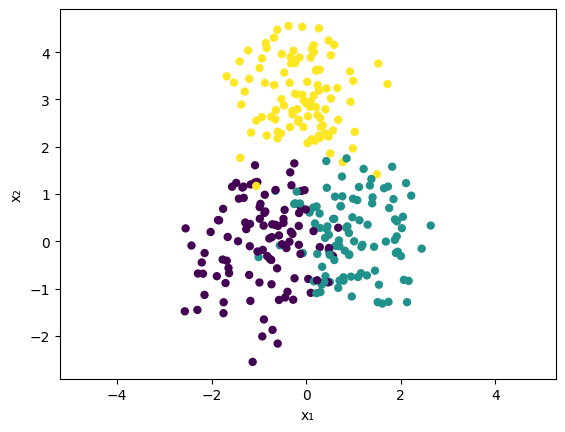

In [110]:
X, y = make_blobs(
    n_samples=300,
    centers=[(-1, 0), (1, 0), (0, 3)],
    cluster_std=0.8,
    random_state=20,
)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=25)
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.axis("equal")
plt.show()

На обучающей выборке:
Для кол-ва соседей =  0 получаем
Верно: 80 из 240 (33.3%)
Для кол-ва соседей =  1 получаем
Верно: 212 из 240 (88.3%)
Для кол-ва соседей =  2 получаем
Верно: 214 из 240 (89.2%)
Для кол-ва соседей =  3 получаем
Верно: 220 из 240 (91.7%)
Для кол-ва соседей =  4 получаем
Верно: 213 из 240 (88.8%)
Для кол-ва соседей =  5 получаем
Верно: 220 из 240 (91.7%)
Для кол-ва соседей =  6 получаем
Верно: 218 из 240 (90.8%)
Для кол-ва соседей =  7 получаем
Верно: 218 из 240 (90.8%)
Для кол-ва соседей =  8 получаем
Верно: 218 из 240 (90.8%)
Для кол-ва соседей =  9 получаем
Верно: 220 из 240 (91.7%)


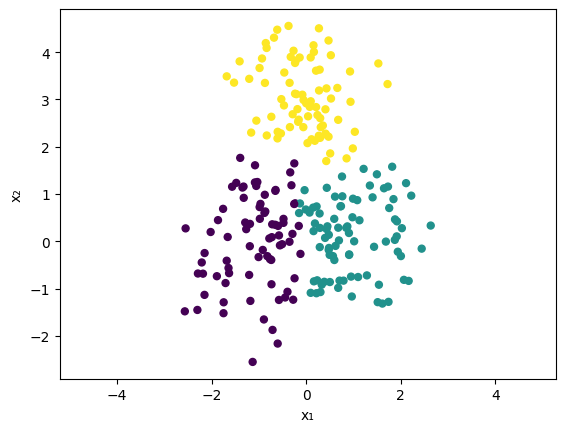

In [111]:
def get_distance(x1, x2):
    return np.sqrt((x1[0] - x2[0]) ** 2 + (x1[1] - x2[1]) ** 2)

def get_train(X, Y, proportion=0.8):
    rng = np.random.default_rng(42)
    idx = rng.permutation(len(X))
    X, Y = X[idx], Y[idx]
    border = int(len(X) * proportion)

    return X[:border], X[border:], Y[:border], Y[border:]
    

def KNN_solution(X, y, neibr=2):
    all_pair = []

    for i in range(len(X)):
        all_distance = np.array([])
        for j in range(len(X)):
            all_distance = np.append(all_distance, get_distance(X[i], X[j]))

        k_neibr = np.empty((len(all_distance), 2))
        for k in range(len(all_distance)):
            k_neibr[k, :1] = all_distance[k]
            k_neibr[k, 1] = y[k]    

        k_neibr = k_neibr[k_neibr[:, 0].argsort()][1:neibr+1]

        count_1 = 0
        count_2 = 0
        count_3 = 0
        for z in range(len(k_neibr)):
            if k_neibr[z][-1] == 0:
                count_1 += 1
            elif k_neibr[z][-1] == 1:
                count_2 += 1
            else:
                count_3 += 1

        sol_for_1_point = max(count_1, count_2, count_3)
        if sol_for_1_point == count_1:
            all_pair.append([X[i], 0])
        elif sol_for_1_point == count_2:
            all_pair.append([X[i], 1])
        else:
            all_pair.append([X[i], 2])

    return all_pair

x_train, x_test, y_train, y_test = get_train(X, y)

print("На обучающей выборке:")
for i in range(10):
    results = KNN_solution(x_train, y_train, i)

    results = np.array([
        [point[0], point[1], label]
        for point, label in results
    ])

    y_pred = results[:, 2]
    correct = y_pred == y_train

    print("Для кол-ва соседей = ", i, "получаем")
    print(f"Верно: {correct.sum()} из {len(correct)} ({correct.mean():.1%})")

plt.scatter(results[:, 0], results[:, 1], c=results[:, 2],
            cmap="viridis", s=25)
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.axis("equal")
plt.show()


k= 1 | обучение: 28/240 ошибок (11.7%) | тест:  8/60 ошибок (13.3%)
k= 2 | обучение: 26/240 ошибок (10.8%) | тест:  7/60 ошибок (11.7%)
k= 3 | обучение: 20/240 ошибок (8.3%) | тест:  7/60 ошибок (11.7%)
k= 4 | обучение: 27/240 ошибок (11.2%) | тест:  7/60 ошибок (11.7%)
k= 5 | обучение: 20/240 ошибок (8.3%) | тест:  7/60 ошибок (11.7%)
k= 6 | обучение: 22/240 ошибок (9.2%) | тест:  7/60 ошибок (11.7%)
k= 7 | обучение: 22/240 ошибок (9.2%) | тест:  9/60 ошибок (15.0%)
k= 8 | обучение: 22/240 ошибок (9.2%) | тест:  8/60 ошибок (13.3%)
k= 9 | обучение: 20/240 ошибок (8.3%) | тест:  8/60 ошибок (13.3%)
k=10 | обучение: 21/240 ошибок (8.8%) | тест:  7/60 ошибок (11.7%)


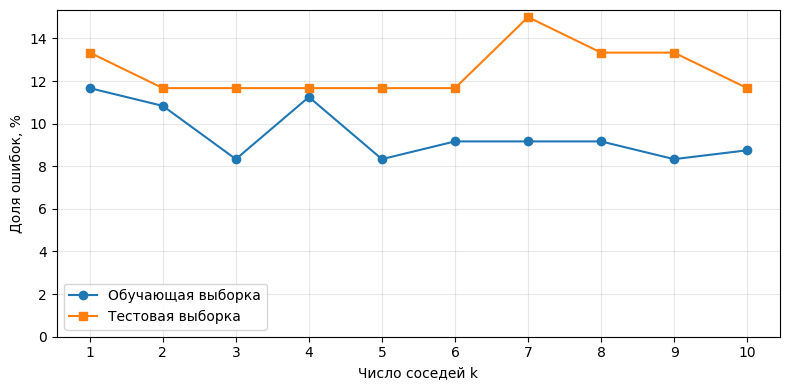

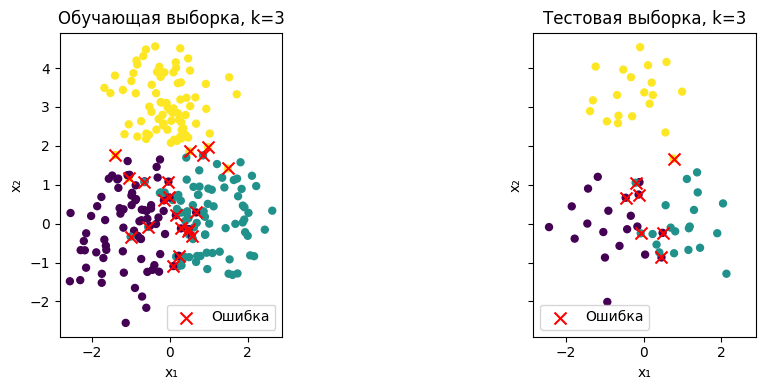

In [112]:
import numpy as np
import matplotlib.pyplot as plt


def get_distance(x1, x2):
    return np.sqrt((x1[0] - x2[0]) ** 2 + (x1[1] - x2[1]) ** 2)


def get_train(X, y, proportion=0.8):
    rng = np.random.default_rng(42)
    idx = rng.permutation(len(X))
    X, y = X[idx], y[idx]
    border = int(len(X) * proportion)
    return X[:border], X[border:], y[:border], y[border:]


def KNN_solution(x_train, y_train, x_query, neibr=3, *, exclude_self=False):
    max_neighbors = len(x_train) - int(exclude_self)
    if not 1 <= neibr <= max_neighbors:
        raise ValueError(f"Число соседей должно быть от 1 до {max_neighbors}")

    predictions = []

    for i, point in enumerate(x_query):
        distances = np.array([
            get_distance(point, train_point)
            for train_point in x_train
        ])

        order = np.argsort(distances, kind="stable")
        if exclude_self:
            order = order[order != i]

        neighbor_labels = y_train[order[:neibr]]
        classes, counts = np.unique(neighbor_labels, return_counts=True)
        predictions.append(classes[np.argmax(counts)])

    return np.array(predictions)


x_train, x_test, y_train, y_test = get_train(X, y)

k_values = range(1, 11)
k_to_show = 3
train_errors = []
test_errors = []

for k in k_values:
    # exclude_self=True используется, когда x_query — сам x_train.
    train_pred = KNN_solution(x_train, y_train, x_train, k, exclude_self=True)
    test_pred = KNN_solution(x_train, y_train, x_test, k)

    train_wrong = train_pred != y_train
    test_wrong = test_pred != y_test

    train_errors.append(100 * train_wrong.mean())
    test_errors.append(100 * test_wrong.mean())

    print(
        f"k={k:2d} | "
        f"обучение: {train_wrong.sum():2d}/{len(y_train)} ошибок "
        f"({train_errors[-1]:.1f}%) | "
        f"тест: {test_wrong.sum():2d}/{len(y_test)} ошибок "
        f"({test_errors[-1]:.1f}%)"
    )

    if k == k_to_show:
        train_wrong_to_show = train_wrong
        test_wrong_to_show = test_wrong

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, train_errors, marker="o", label="Обучающая выборка")
ax.plot(k_values, test_errors, marker="s", label="Тестовая выборка")
ax.set_xticks(list(k_values))
ax.set_xlabel("Число соседей k")
ax.set_ylabel("Доля ошибок, %")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
classes = np.unique(y)

for ax, points, labels, wrong, title in (
    (axes[0], x_train, y_train, train_wrong_to_show, "Обучающая выборка"),
    (axes[1], x_test, y_test, test_wrong_to_show, "Тестовая выборка"),
):
    ax.scatter(
        points[:, 0], points[:, 1], c=labels, cmap="viridis", s=25,
        vmin=classes.min(), vmax=classes.max(),
    )
    ax.scatter(
        points[wrong, 0], points[wrong, 1],
        color="red", marker="x", s=75, label="Ошибка",
    )
    ax.set_title(f"{title}, k={k_to_show}")
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.set_aspect("equal", adjustable="box")
    ax.legend()

fig.tight_layout()
plt.show()